In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import numpy as np
import os
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#veri setini hazırlama

# Veri setinin yolu
data_dir = "/content/drive/MyDrive/image_processing"  # "yes" ve "no" klasörleri burada olmalı

# Görüntüleri ve etiketleri yükle
images = []
labels = []

for label, class_name in enumerate(["no", "yes"]):
    class_dir = os.path.join(data_dir, class_name)
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)
        img = tf.keras.preprocessing.image.load_img(img_path, target_size=(150, 150))
        img_array = tf.keras.preprocessing.image.img_to_array(img)
        images.append(img_array)
        labels.append(label)

# Listeleri numpy array'ine dönüştür
images = np.array(images)
labels = np.array(labels)

# Veri setini eğitim ve test olarak böl (örneğin, %80 eğitim, %20 test)
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.2, random_state=42)

# Normalizasyon (0-255 arası değerleri 0-1 arasına ölçekle)
X_train = X_train / 255.0
X_test = X_test / 255.0

In [4]:
#CNN modeli pluşturma

model = Sequential()

# 1. konvolüsyonel Katman + maxpooling
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# 2. konvolüsyonel Katman + maxpooling
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# 3. konvolüsyonel Katman + maxpooling
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Düzleştirme (flatten) Katman
model.add(Flatten())

# Tam Bağlantılı (dense) Katman + dropout
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))

# Çıkış Katmanı
model.add(Dense(1, activation='sigmoid'))

# Modeli Derle
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Model Özeti
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,034,177 (72.61 MB)

 Trainable params: 19,034,177 (72.61 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
#modeli eğit

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 846ms/step - accuracy: 0.4652 - loss: 1.1985 - val_accuracy: 0.7647 - val_loss: 0.6124
Epoch 2/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7686 - loss: 0.5644 - val_accuracy: 0.7255 - val_loss: 0.6680
Epoch 3/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7920 - loss: 0.4694 - val_accuracy: 0.7451 - val_loss: 0.6243
Epoch 4/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8085 - loss: 0.4574 - val_accuracy: 0.7059 - val_loss: 0.5396
Epoch 5/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8274 - loss: 0.3805 - val_accuracy: 0.7451 - val_loss: 0.6506
Epoch 6/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8425 - loss: 0.3983 - val_accuracy: 0.7451 - val_loss: 0.5224
Epoch 7/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8688 - loss: 0.2896 - val_accuracy: 0.7647 - val_loss: 0.4916
Epoch 8/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9075 - loss: 0.2396 - val_accuracy: 0.7451 - val_loss: 0.509

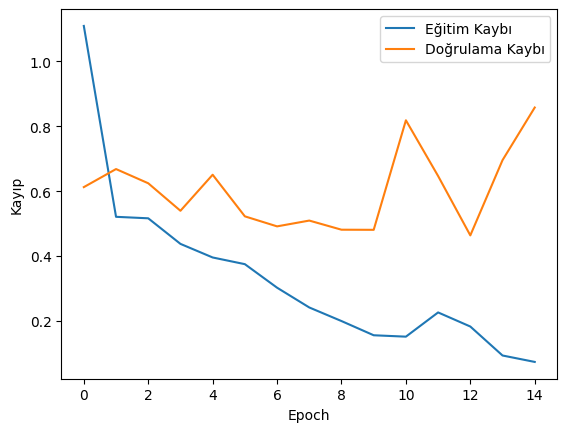

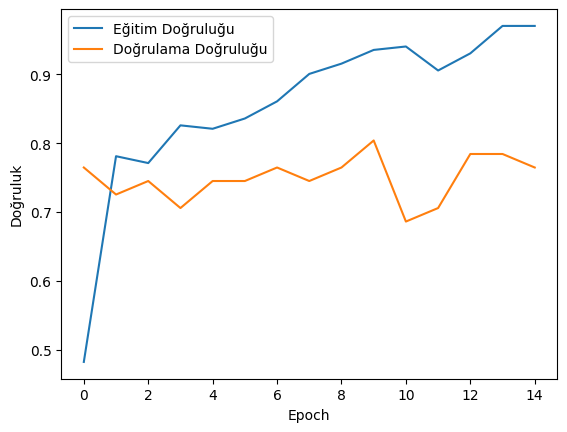

In [6]:
#modeli değerlendir

# Eğitim ve doğrulama kaybını çiz
plt.plot(history.history['loss'], label='Eğitim Kaybı')
plt.plot(history.history['val_loss'], label='Doğrulama Kaybı')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.legend()
plt.show()

# Eğitim ve doğrulama doğruluğunu çiz
plt.plot(history.history['accuracy'], label='Eğitim Doğruluğu')
plt.plot(history.history['val_accuracy'], label='Doğrulama Doğruluğu')
plt.xlabel('Epoch')
plt.ylabel('Doğruluk')
plt.legend()
plt.show()

In [7]:
# Test veri seti üzerinde modeli değerlendir (Test)
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Doğruluğu: {test_acc:.2f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7702 - loss: 0.7923
Test Doğruluğu: 0.76


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Tümör Var


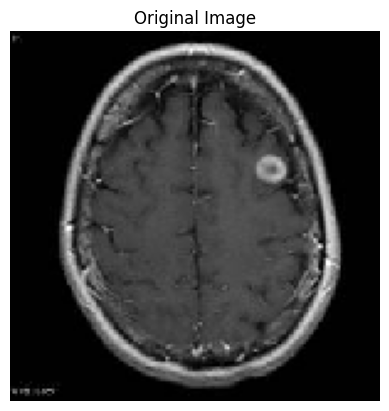

In [12]:
#Yeni görüntüler üzerinden Tahmin yap

import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Yeni bir görüntü yükle
img_path = "/content/drive/MyDrive/image_processing/images/Image10.jpg"
img = image.load_img(img_path, target_size=(150, 150))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array /= 255.0

# Tahmin yap
prediction = model.predict(img_array)
if prediction[0] > 0.5:
    print("Tümör Var")
else:
    print("Tümör Yok")

plt.imshow(img)
plt.title("Original Image")
plt.axis('off')
plt.show()